In [1]:
import pandas as pd
import numpy as np
import pandas as pd
import csv
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from itertools import combinations
from scipy.stats import mannwhitneyu

In [2]:
sgb_details = pd.read_csv('/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/sgb_details_allRaxml_new_testing.csv')
sgb_details.head()

,triad_id,dataset,display_dataset,donor_id,pre_fmt_id,post_fmt_id,post_timepoint,original_donor_string,donor_sgbs,pre_sgbs,post_sgbs,shared_donor_post_sgbs,shared_donor_pre_sgbs,shared_post_pre_sgbs,n_donor_sgbs,n_pre_sgbs,n_post_sgbs,n_shared_donor_post,n_shared_donor_pre,n_shared_post_pre
0,SRS9474922_SRS9474920,AggarwalaV_2021,AggarwalaV_2021,SRS9474972,SRS9474920,SRS9474922,33,SRS9474972,"t__SGB14809,t__SGB14853,t__SGB14862,t__SGB1499...","t__SGB10068,t__SGB15271,t__SGB17234,t__SGB1724...","t__SGB14535_group,t__SGB15342,t__SGB17244,t__S...","t__SGB15342,t__SGB17248,t__SGB1814,t__SGB1855,...",NaN,NaN,71,6,14,10,0,0
1,SRS9474925_SRS9474898,AggarwalaV_2021,AggarwalaV_2021,SRS9474924,SRS9474898,SRS9474925,7,SRS9474924,"t__SGB14797,t__SGB14808,t__SGB14809,t__SGB1484...","t__SGB10028,t__SGB10068,t__SGB10115_group,t__S...","t__SGB15346,t__SGB1871,t__SGB5082","t__SGB15346,t__SGB1871,t__SGB5082",NaN,NaN,67,7,3,3,0,0
2,SRS9474934_SRS9474930,AggarwalaV_2021,AggarwalaV_2021,SRS9474895,SRS9474930,SRS9474934,44,SRS9474895,"t__SGB13977,t__SGB14215,t__SGB143306,t__SGB145...",t__SGB14014,"t__SGB14535_group,t__SGB15318,t__SGB15322,t__S...","t__SGB14535_group,t__SGB15322,t__SGB15332,t__S...",NaN,NaN,98,1,20,13,0,0
3,SRS9474909_SRS9474897,AggarwalaV_2021,AggarwalaV_2021,SRS9474906,SRS9474897,SRS9474909,45,SRS9474906,"t__SGB14124,t__SGB14250,t__SGB14306,t__SGB1433...","t__SGB10068,t__SGB10075,t__SGB15078,t__SGB1513...","t__SGB14306,t__SGB14861,t__SGB15093,t__SGB1523...","t__SGB14306,t__SGB14861,t__SGB15093,t__SGB1523...","t__SGB15316,t__SGB15373,t__SGB4933,t__SGB5068","t__SGB4198,t__SGB5068",134,29,27,19,4,2
4,SRS9474952_SRS9474948,AggarwalaV_2021,AggarwalaV_2021,SRS9474939,SRS9474948,SRS9474952,27,SRS9474939,"t__SGB14114,t__SGB14306,t__SGB14307,t__SGB1431...",t__SGB10068,"t__SGB15286,t__SGB15300,t__SGB15332,t__SGB1534...","t__SGB15286,t__SGB15300,t__SGB15342,t__SGB1723...",NaN,NaN,148,1,26,16,0,0


In [3]:
metadata = pd.read_csv(
    '/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/strain_share_newrun_June26/triads_cleaned_1gbp.csv',
    # sep='\t',
    # quoting=csv.QUOTE_NONE,
    # engine='python'
)

metadata.head()

,fmt_id,dataset,recipient_name,donor_name,pre_samples,post_samples,donor_sample,display_dataset,disease_indication,single_pre_sample,single_post_sample,single_post_timepoint,single_donor_sample,success,fresh_frozen,related_donor,route_binary,route,abx,BOWEL PREP
0,1,AggarwalaV_2021,1001166,1001175,1001166B,1001166G,1001175B,AggarwalaV_2021,rCDI,SRS9474920,SRS9474922,33,SRS9474972,True,both,unrelated,NaN,colonoscopy or nasogastric tube,TRUE,bowel prep (unspecified)
1,2,AggarwalaV_2021,1001216,1001217,1001216B,"1001216F,1001216H,1001216I",1001217B,AggarwalaV_2021,rCDI,SRS9474898,SRS9474925,7,SRS9474924,False,both,unrelated,NaN,colonoscopy or nasogastric tube,TRUE,bowel prep (unspecified)
2,3,AggarwalaV_2021,1001254,1001262,"1001254A,1001254B","1001254E,1001254F,1001254G,1001254H,1001254I,1...",1001262B,AggarwalaV_2021,rCDI,SRS9474930,SRS9474934,44,SRS9474895,True,both,unrelated,NaN,colonoscopy or nasogastric tube,TRUE,bowel prep (unspecified)
3,4,AggarwalaV_2021,1001270,1001271,1001270B,"1001270D,1001270F,1001270H,1001270J",1001271B,AggarwalaV_2021,rCDI,SRS9474897,SRS9474909,45,SRS9474906,True,both,unrelated,NaN,colonoscopy or nasogastric tube,TRUE,bowel prep (unspecified)
4,5,AggarwalaV_2021,1001282,1001283,1001282B,"1001282G,1001282H",1001283B,AggarwalaV_2021,rCDI,SRS9474948,SRS9474952,27,SRS9474939,True,both,unrelated,NaN,colonoscopy or nasogastric tube,TRUE,bowel prep (unspecified)


In [4]:
import pandas as pd
import numpy as np

# ----------------------------------------------------------------------
# 1. Define placebo triads (dataset, pre_fmt_id pairs)
# ----------------------------------------------------------------------
placebo_pairs = [
    ('PorcariS_2026', 'FMT_T003_t0'), ('PorcariS_2026', 'FMT_T006_t0'),
    ('PorcariS_2026', 'FMT_T008_t0'), ('PorcariS_2026', 'FMT_T012_t0'),
    ('PorcariS_2026', 'FMT_T014_t0'), ('PorcariS_2026', 'FMT_T016_t0'),
    ('PorcariS_2026', 'FMT_T018_t0'), ('PorcariS_2026', 'FMT_T020_t0'),
    ('PorcariS_2026', 'FMT_T021_t0'), ('PorcariS_2026', 'FMT_T025_t0'),
    ('PorcariS_2026', 'FMT_T028_t0'), ('PorcariS_2026', 'FMT_T029_t0'),
    ('PorcariS_2026', 'FMT_T034_t0'), ('PorcariS_2026', 'FMT_T035_t0'),
    ('PorcariS_2026', 'FMT_T037_t0'), ('PorcariS_2026', 'FMT_T040_t0'),
    ('PorcariS_2026', 'FMT_T042_t0'), ('PorcariS_2026', 'FMT_T046_t0'),
    ('PorcariS_2026', 'FMT_T047_t0'), ('PorcariS_2026', 'FMT_T051_t0'),
    ('PorcariS_2026', 'FMT_T052_t0'), ('PorcariS_2026', 'FMT_T053_t0'),
    ('PorcariS_2026', 'FMT_T054_t0'), ('PorcariS_2026', 'FMT_T002_t0'),
    ('ShekarrizS_2025', 'SRR32260085'), ('ShekarrizS_2025', 'SRR32260076'),
    ('ShekarrizS_2025', 'SRR32260078'), ('ShekarrizS_2025', 'SRR32260093'),
    ('NgS_2021', 'SRR14306940'), ('NgS_2021', 'SRR14306931'),
    ('NgS_2021', 'SRR14306924'), ('NgS_2021', 'SRR14306906'),
    ('NgS_2021', 'SRR14306890'), ('NgS_2021', 'SRR14306877'),
    ('NgS_2021', 'SRR14322015'), ('NgS_2021', 'SRR14321949'),
    ('NgS_2021', 'SRR14321999'), ('NgS_2021', 'SRR14321994'),
    ('NgS_2021', 'SRR14321979'), ('NgS_2021', 'SRR14321966'),
    ('NgS_2021', 'SRR14321962'), ('NgS_2021', 'SRR14321957'),
    ('NgS_2021', 'SRR14368374'), ('NgS_2021', 'SRR14368370'),
    ('NgS_2021', 'SRR14368339'), ('NgS_2021', 'SRR14368335'),
    ('NgS_2021', 'SRR14368326'), ('NgS_2021', 'SRR14368322'),
    ('NgS_2021', 'SRR14368317'), 
    ('WoodworthM_2023', 'SRR14871937'), 
    ('WoodworthM_2023', 'SRR14871906'), ('WoodworthM_2023', 'SRR14871888')
]

PORCARI_REFERENCE_DONOR = 'FMT_DTT001_100921'

placebo_df_check = pd.DataFrame(placebo_pairs, columns=['display_dataset', 'pre_fmt_id'])
print(f"Total placebo triads specified: {len(placebo_df_check)}")

# ----------------------------------------------------------------------
# 2. Flag placebo rows directly in sgb_details
# ----------------------------------------------------------------------

# Standard placebo classification
sgb_details['is_placebo'] = sgb_details.apply(
    lambda row: (
        row['display_dataset'],
        row['pre_fmt_id']
    ) in placebo_pairs,
    axis=1
)

# Special Woodworth exception:
# Same pre-FMT ID occurs in both treatment and placebo triads.
# Identify the placebo specifically by its post-FMT sample ID.

woodworth_exception = (
    (sgb_details['display_dataset'] == 'WoodworthM_2023') &
    (sgb_details['pre_fmt_id'].astype(str).str.strip() == 'SRR14871907') &
    (sgb_details['post_fmt_id'].astype(str).str.strip() == 'SRR14868461')
)

sgb_details.loc[woodworth_exception, 'is_placebo'] = True

# Verify classification
print("\n=== Woodworth classification check ===")

print(
    sgb_details.loc[
        (sgb_details['display_dataset'] == 'WoodworthM_2023') &
        (sgb_details['pre_fmt_id'].astype(str).str.strip() == 'SRR14871907'),
        ['triad_id', 'pre_fmt_id', 'post_fmt_id', 'is_placebo']
    ].to_string(index=False)
)

print(f"\nWoodworth placebo exception matches: {woodworth_exception.sum()}")

# Check missing placebo pairs
matched_triads = set(zip(
    sgb_details.loc[sgb_details['is_placebo'], 'display_dataset'],
    sgb_details.loc[sgb_details['is_placebo'], 'pre_fmt_id']
))

missing = set(placebo_pairs) - matched_triads

if missing:
    print(f"\nWARNING: {len(missing)} placebo pairs not found:")
    for m in sorted(missing):
        print(f"  {m}")

# Split treatment and placebo
treatment_sgb = sgb_details[~sgb_details['is_placebo']].copy()
placebo_sgb = sgb_details[sgb_details['is_placebo']].copy()

print("\n=== Final classification ===")
print(f"Treatment rows: {len(treatment_sgb)}")
print(f"Placebo rows:   {len(placebo_sgb)}")
print("\nTriads by dataset and arm:")

print(
    pd.concat([
        treatment_sgb.assign(arm='treatment'),
        placebo_sgb.assign(arm='placebo')
    ])
    .groupby(['display_dataset', 'arm'])['triad_id']
    .nunique()
    .unstack(fill_value=0)
)
# ----------------------------------------------------------------------
# 3. Helper: union-based multi-donor aggregation (for NgS_2021 /
#    ShekarrizS_2025 placebo triads, which may have several candidate
#    donor rows per triad_id)
# ----------------------------------------------------------------------
def aggregate_multi_donor(df):
    results = []
    for triad_id, group in df.groupby('triad_id'):
        all_donor_sgbs = set()
        per_donor_counts = []
        for donor_sgbs_str in group['donor_sgbs']:
            if pd.notna(donor_sgbs_str) and donor_sgbs_str != '':
                sgbs = set(donor_sgbs_str.split(','))
                all_donor_sgbs.update(sgbs)
                per_donor_counts.append(len(sgbs))
            else:
                per_donor_counts.append(0)

        median_donor_sgbs = np.median(per_donor_counts) if per_donor_counts else np.nan

        unique_shared_donor_post = set()
        for s in group['shared_donor_post_sgbs']:
            if pd.notna(s) and s != '':
                unique_shared_donor_post.update(s.split(','))

        unique_shared_donor_pre = set()
        for s in group['shared_donor_pre_sgbs']:
            if pd.notna(s) and s != '':
                unique_shared_donor_pre.update(s.split(','))

        results.append({
            'triad_id': triad_id,
            'dataset': group['dataset'].iloc[0],
            'display_dataset': group['display_dataset'].iloc[0],
            'donor_id': ','.join(sorted(group['donor_id'].dropna().astype(str).unique())),
            'pre_fmt_id': group['pre_fmt_id'].iloc[0],
            'post_fmt_id': group['post_fmt_id'].iloc[0],
            'post_timepoint': group['post_timepoint'].iloc[0],
            'donor_sgb_denom': median_donor_sgbs,
            'n_donor_sgbs_union': len(all_donor_sgbs),
            'n_pre_sgbs': group['n_pre_sgbs'].iloc[0],
            'n_post_sgbs': group['n_post_sgbs'].iloc[0],
            'n_shared_donor_post': len(unique_shared_donor_post),
            'n_shared_donor_pre': len(unique_shared_donor_pre),
            'n_shared_post_pre': group['n_shared_post_pre'].iloc[0],
        })
    return pd.DataFrame(results)

# ----------------------------------------------------------------------
# 4. Helper: single-donor direct lookup (for treatment, all datasets;
#    and PorcariS_2026 placebo, restricted to the reference donor)
# ----------------------------------------------------------------------
def aggregate_single_donor(df, context_label):
    dup_counts = df.groupby('triad_id').size()
    n_dupes = (dup_counts > 1).sum()
    if n_dupes > 0:
        print(f"WARNING [{context_label}]: {n_dupes} triad_id(s) had more than "
              f"1 row where exactly 1 was expected — taking the first row for each.")

    out = df.drop_duplicates(subset='triad_id', keep='first').copy()
    out['donor_sgb_denom'] = out['n_donor_sgbs']
    return out[[
        'triad_id', 'dataset', 'display_dataset', 'donor_id',
        'pre_fmt_id', 'post_fmt_id', 'post_timepoint',
        'donor_sgb_denom', 'n_pre_sgbs', 'n_post_sgbs',
        'n_shared_donor_post', 'n_shared_donor_pre', 'n_shared_post_pre'
    ]].rename(columns={'n_donor_sgbs': 'n_donor_sgbs_union'})  # kept absent; placeholder not used

# ----------------------------------------------------------------------
# 5. Build the pieces
# ----------------------------------------------------------------------
MULTI_DONOR_DS  = ['NgS_2021', 'ShekarrizS_2025']
SINGLE_DONOR_DS = ['PorcariS_2026', 'WoodworthM_2023']   # <-- Woodworth added

pieces = []

# 5a. Treatment, single-donor datasets
for ds in SINGLE_DONOR_DS:
    raw = treatment_sgb[treatment_sgb['display_dataset'] == ds].copy()
    if len(raw):
        agg = aggregate_single_donor(raw, f'treatment-{ds}')
        agg['arm'] = 'treatment'
        pieces.append(agg)

# 5b. Treatment, multi-donor datasets
raw = treatment_sgb[treatment_sgb['display_dataset'].isin(MULTI_DONOR_DS)].copy()
if len(raw):
    agg = aggregate_multi_donor(raw)
    agg['arm'] = 'treatment'
    pieces.append(agg)

# 5c. Placebo, Porcari: restrict to the reference donor
raw = placebo_sgb[
    (placebo_sgb['display_dataset'] == 'PorcariS_2026') &
    (placebo_sgb['donor_id'] == PORCARI_REFERENCE_DONOR)
].copy()
n_expected = (placebo_df_check['display_dataset'] == 'PorcariS_2026').sum()
print(f"\nPorcariS_2026 placebo: matched {raw['triad_id'].nunique()} triads "
      f"against donor {PORCARI_REFERENCE_DONOR} (expected up to {n_expected})")
agg = aggregate_single_donor(raw, 'placebo-PorcariS_2026')
agg['arm'] = 'placebo'
pieces.append(agg)

# 5d. Placebo, Woodworth: single donor taken from metadata, no filter
raw = placebo_sgb[placebo_sgb['display_dataset'] == 'WoodworthM_2023'].copy()
n_expected = (placebo_df_check['display_dataset'] == 'WoodworthM_2023').sum()
print(f"WoodworthM_2023 placebo: matched {raw['triad_id'].nunique()} triads "
      f"(expected {n_expected})")
agg = aggregate_single_donor(raw, 'placebo-WoodworthM_2023')
agg['arm'] = 'placebo'
pieces.append(agg)

# 5e. Placebo, multi-donor datasets
raw = placebo_sgb[placebo_sgb['display_dataset'].isin(MULTI_DONOR_DS)].copy()
agg = aggregate_multi_donor(raw)
agg['arm'] = 'placebo'
pieces.append(agg)

# ----------------------------------------------------------------------
# 6. Combine
# ----------------------------------------------------------------------
aggregated = pd.concat(pieces, ignore_index=True)

# ----------------------------------------------------------------------
# 7. Compute DoSER pre/post from the unified denominator column
# ----------------------------------------------------------------------
aggregated['doser_pre'] = aggregated.apply(
    lambda row: row['n_shared_donor_pre'] / row['donor_sgb_denom']
    if pd.notna(row['donor_sgb_denom']) and row['donor_sgb_denom'] > 0
    else np.nan,
    axis=1
)
aggregated['doser_post'] = aggregated.apply(
    lambda row: row['n_shared_donor_post'] / row['donor_sgb_denom']
    if pd.notna(row['donor_sgb_denom']) and row['donor_sgb_denom'] > 0
    else np.nan,
    axis=1
)

print(f"\nFinal aggregated table: {len(aggregated)} triads")
print(aggregated['arm'].value_counts())
print(aggregated.groupby(['display_dataset', 'arm']).size())

aggregated.head()

Total placebo triads specified: 52

=== Woodworth classification check ===
               triad_id  pre_fmt_id post_fmt_id  is_placebo
SRR14871874_SRR14871907 SRR14871907 SRR14871874       False
SRR14868461_SRR14871907 SRR14871907 SRR14868461        True

Woodworth placebo exception matches: 1

  ('NgS_2021', 'SRR14306890')
  ('PorcariS_2026', 'FMT_T003_t0')

=== Final classification ===
Treatment rows: 1028
Placebo rows:   304

Triads by dataset and arm:
arm                     placebo  treatment
display_dataset                           
AggarwalaV_2021               0          9
BarYosephH_2020               0          7
BaruchE_2020                  0         10
ChenK_2026                    0         11
DammanC_2015                  0          6
DavarD_2021                   0         14
DuttaguptaS_2026_Mel          0         19
DuttaguptaS_2026_NSCLC        0         18
FernandesR_2026               0         19
GollR_2020                    0         20
GoloshchapovO_2019      

,triad_id,dataset,display_dataset,donor_id,pre_fmt_id,post_fmt_id,post_timepoint,donor_sgb_denom,n_pre_sgbs,n_post_sgbs,n_shared_donor_post,n_shared_donor_pre,n_shared_post_pre,arm,n_donor_sgbs_union,doser_pre,doser_post
0,FMT_T009_t30_FMT_T009_t0,CM_IaniroFMT5,PorcariS_2026,FMT_DTT001_t0,FMT_T009_t0,FMT_T009_t30,30,94.0,70,153,33,1,13,treatment,NaN,0.010638,0.351064
1,FMT_T011_t30_FMT_T011_t0,CM_IaniroFMT5,PorcariS_2026,FMT_DTT001_100921,FMT_T011_t0,FMT_T011_t30,30,143.0,152,186,43,1,59,treatment,NaN,0.006993,0.300699
2,FMT_T013_t30_FMT_T013_t0,CM_IaniroFMT5,PorcariS_2026,FMT_DTT001_100921,FMT_T013_t0,FMT_T013_t30,30,143.0,91,115,42,2,38,treatment,NaN,0.013986,0.293706
3,FMT_T015_t30_FMT_T015_t0,CM_IaniroFMT5,PorcariS_2026,FMT_DTT005_101121,FMT_T015_t0,FMT_T015_t30,30,133.0,106,100,28,7,37,treatment,NaN,0.052632,0.210526
4,FMT_T017_t30_FMT_T017_t0,CM_IaniroFMT5,PorcariS_2026,FMT_DTT001_100921,FMT_T017_t0,FMT_T017_t30,30,143.0,134,108,3,2,58,treatment,NaN,0.013986,0.020979



=== PorcariS_2026: Stats ===
                    comparison         test      p_value
  Pre placebo vs Pre treatment Mann-Whitney 8.246256e-01
Post placebo vs Post treatment Mann-Whitney 2.110674e-08
           Placebo pre vs post     Wilcoxon 2.566039e-01
         Treatment pre vs post     Wilcoxon 2.698702e-05


/tmp/ipykernel_1399117/4088647604.py:155: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


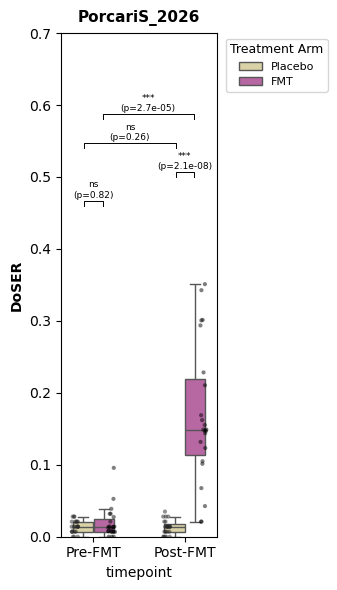


=== ShekarrizS_2025: Stats ===
                    comparison         test  p_value
  Pre placebo vs Pre treatment Mann-Whitney 1.000000
Post placebo vs Post treatment Mann-Whitney 0.773384
           Placebo pre vs post     Wilcoxon 0.500000
         Treatment pre vs post     Wilcoxon 0.031250


/tmp/ipykernel_1399117/4088647604.py:155: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


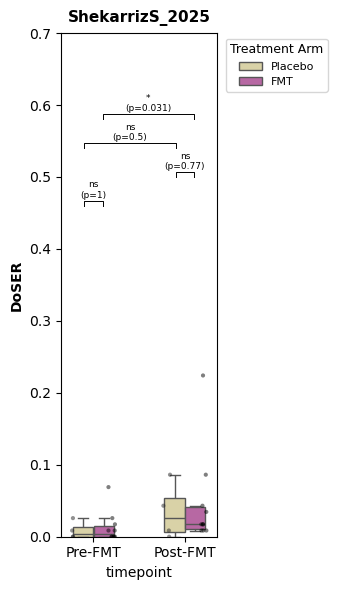


=== NgS_2021: Stats ===
                    comparison         test      p_value
  Pre placebo vs Pre treatment Mann-Whitney 5.453626e-01
Post placebo vs Post treatment Mann-Whitney 1.201133e-06
           Placebo pre vs post     Wilcoxon 3.194274e-01
         Treatment pre vs post     Wilcoxon 5.253038e-07


/tmp/ipykernel_1399117/4088647604.py:155: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


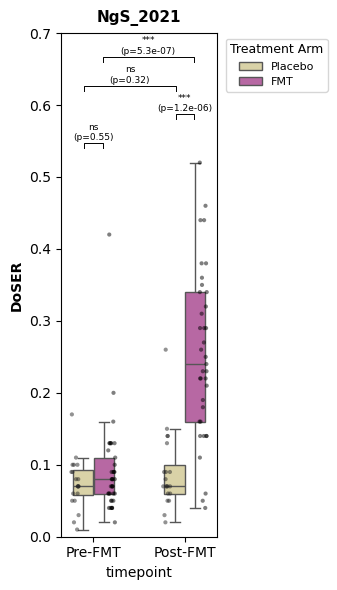

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from itertools import combinations
from scipy.stats import mannwhitneyu, wilcoxon

# ----------------------------------------------------------------------
# `aggregated` already has: display_dataset, pre_fmt_id, arm, doser_pre,
# doser_post — built in the previous cell. No need to re-split placebo/
# treatment or recompute doser here.
# ----------------------------------------------------------------------
datasets_to_plot = ['PorcariS_2026', 'ShekarrizS_2025', 'NgS_2021']

wide_df = aggregated[aggregated['display_dataset'].isin(datasets_to_plot)].copy()

long_df = pd.melt(
    wide_df,
    id_vars=['display_dataset', 'arm', 'pre_fmt_id'],
    value_vars=['doser_pre', 'doser_post'],
    var_name='timepoint', value_name='doser'
)
long_df['timepoint'] = long_df['timepoint'].map({'doser_pre': 'pre', 'doser_post': 'post'})
long_df['display_dataset'] = pd.Categorical(long_df['display_dataset'],
                                             categories=datasets_to_plot, ordered=True)

# 4 groups per dataset, in plot order
group_order = [('pre', 'placebo'), ('pre', 'treatment'), ('post', 'placebo'), ('post', 'treatment')]

def sig_marker(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

# ----------------------------------------------------------------------
# Pairwise Mann-Whitney across all 6 combinations of the 4 groups,
# for a single dataset
# ----------------------------------------------------------------------
def run_statistics(sub_df):

    results = []

    # --------------------------------------------------
    # Mann-Whitney: placebo vs treatment at PRE
    # --------------------------------------------------
    pre_placebo = sub_df.loc[
        (sub_df.timepoint == "pre") &
        (sub_df.arm == "placebo"),
        "doser"
    ].dropna()

    pre_treatment = sub_df.loc[
        (sub_df.timepoint == "pre") &
        (sub_df.arm == "treatment"),
        "doser"
    ].dropna()

    U, p = mannwhitneyu(pre_placebo, pre_treatment, alternative="two-sided")

    results.append({
        "comparison": "Pre placebo vs Pre treatment",
        "test": "Mann-Whitney",
        "p_value": p
    })

    # --------------------------------------------------
    # Mann-Whitney: placebo vs treatment at POST
    # --------------------------------------------------
    post_placebo = sub_df.loc[
        (sub_df.timepoint == "post") &
        (sub_df.arm == "placebo"),
        "doser"
    ].dropna()

    post_treatment = sub_df.loc[
        (sub_df.timepoint == "post") &
        (sub_df.arm == "treatment"),
        "doser"
    ].dropna()

    U, p = mannwhitneyu(post_placebo, post_treatment, alternative="two-sided")

    results.append({
        "comparison": "Post placebo vs Post treatment",
        "test": "Mann-Whitney",
        "p_value": p
    })

    # --------------------------------------------------
    # Wilcoxon: PRE vs POST within each arm
    # --------------------------------------------------
    for arm in ["placebo", "treatment"]:

        arm_df = (
            sub_df[sub_df.arm == arm]
            .pivot(index="pre_fmt_id",
                   columns="timepoint",
                   values="doser")
            .dropna()
        )

        if len(arm_df):

            stat, p = wilcoxon(
                arm_df["pre"],
                arm_df["post"]
            )

        else:
            p = np.nan

        results.append({
            "comparison": f"{arm.capitalize()} pre vs post",
            "test": "Wilcoxon",
            "p_value": p
        })

    return pd.DataFrame(results)

# ----------------------------------------------------------------------
# Plot one dataset: 4 bars (pre-placebo, pre-treatment, post-placebo,
# post-treatment) with box+strip, plus stacked significance brackets
# for all 6 pairwise comparisons.
# ----------------------------------------------------------------------
def plot_dataset(ds):
    sub_df = long_df[long_df['display_dataset'] == ds].copy()
    stats_df = run_statistics(sub_df)

    print(f"\n=== {ds}: Stats ===")
    print(stats_df.to_string(index=False))

    # tighter figure dimensions
    fig, ax = plt.subplots(figsize=(3.5, 6))

    sns.boxplot(
        data=sub_df,
        x='timepoint',
        y='doser',
        hue='arm',
        order=['pre', 'post'],
        hue_order=['placebo', 'treatment'],
        ax=ax,
        width=0.45,
        dodge=True,
        gap=0.02,
        palette={'placebo': '#E1D89F', 'treatment': '#C45BAA'},
        fliersize=0
    )

    sns.stripplot(
        data=sub_df,
        x='timepoint',
        y='doser',
        hue='arm',
        order=['pre', 'post'],
        hue_order=['placebo', 'treatment'],
        ax=ax,
        dodge=True,
        jitter=0.08,
        size=3,
        color='black',
        alpha=0.5,
        legend=False
    )

    # compressed x positions for significance brackets
    x_pos = {
        ('pre', 'placebo'): -0.10,
        ('pre', 'treatment'): 0.10,
        ('post', 'placebo'): 0.90,
        ('post', 'treatment'): 1.10,
    }

    
    comparisons = [
        ("Pre placebo vs Pre treatment",
         ('pre', 'placebo'),
         ('pre', 'treatment')),
    
        ("Post placebo vs Post treatment",
         ('post', 'placebo'),
         ('post', 'treatment')),
    
        ("Placebo pre vs post",
         ('pre', 'placebo'),
         ('post', 'placebo')),
    
        ("Treatment pre vs post",
         ('pre', 'treatment'),
         ('post', 'treatment')),
    ]
    
    # --------------------------------------------------
    # Fixed y-axis with adaptive significance brackets
    # --------------------------------------------------
    YMAX = 0.7
    
    highest_point = sub_df["doser"].max()
    
    # Place brackets just above the tallest point, but
    # don't let them start lower than 0.46
    base_y = max(highest_point + 0.02, 0.46)
    
    step = 0.040
    h = 0.007
    
    # If the highest bracket would exceed the plotting area,
    # shift the whole stack downward.
    top_needed = base_y + (len(comparisons) - 1) * step + h
    if top_needed > (YMAX - 0.01):
        base_y -= top_needed - (YMAX - 0.01)

   
    for i, (comparison, g1, g2) in enumerate(comparisons):
    
        p = stats_df.loc[
            stats_df["comparison"] == comparison,
            "p_value"
        ].iloc[0]
    
        x1 = x_pos[g1]
        x2 = x_pos[g2]
    
        y = base_y + i * step
        # h = y_range * 0.018
    
        ax.plot(
            [x1, x1, x2, x2],
            [y, y+h, y+h, y],
            color="black",
            linewidth=0.7
        )
    
        ax.text(
            (x1+x2)/2,
            y+h*1.2,
            f"{sig_marker(p)}\n(p={p:.2g})",
            ha="center",
            va="bottom",
            fontsize=6.5
        )
    # formatting
    ax.set_xlim(-0.35, 1.35)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(
        ['Pre-FMT', 'Post-FMT'],
        fontsize=10
    )
    ax.set_ylabel(
        'DoSER',
        fontsize=10,
        fontweight='bold'
    )

    ax.set_title(
        ds,
        fontsize=11,
        fontweight='bold',
        pad=8
    )

    handles, labels = ax.get_legend_handles_labels()

    # Keep only the first two entries (boxplot legend)
    handles = handles[:2]
    labels = ["Placebo", "FMT"]
    
    ax.legend(
        handles,
        labels,
        title="Treatment Arm",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8,
        title_fontsize=9
    )

    # ax.set_ylim(
    #     top=base_y + len(comparisons)*step + y_range*0.12
    # )
    ax.set_ylim(0, 0.7)

    plt.tight_layout()

    fig.savefig(
        f"{ds}_engraftment_by_treatment_arm.png",
        dpi=300,
        bbox_inches="tight"
    )
    
    plt.show()
    

    return comparisons

all_mw_results = {}
for ds in datasets_to_plot:
    all_mw_results[ds] = plot_dataset(ds)


=== PorcariS_2026: Stats ===
                    comparison         test      p_value
  Pre placebo vs Pre treatment Mann-Whitney 8.246256e-01
Post placebo vs Post treatment Mann-Whitney 2.110674e-08
           Placebo pre vs post     Wilcoxon 2.566039e-01
         Treatment pre vs post     Wilcoxon 2.698702e-05


/tmp/ipykernel_1399117/2715206476.py:81: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(



=== ShekarrizS_2025: Stats ===
                    comparison         test  p_value
  Pre placebo vs Pre treatment Mann-Whitney 1.000000
Post placebo vs Post treatment Mann-Whitney 0.773384
           Placebo pre vs post     Wilcoxon 0.500000
         Treatment pre vs post     Wilcoxon 0.031250

=== NgS_2021: Stats ===
                    comparison         test      p_value
  Pre placebo vs Pre treatment Mann-Whitney 5.453626e-01
Post placebo vs Post treatment Mann-Whitney 1.201133e-06
           Placebo pre vs post     Wilcoxon 3.194274e-01
         Treatment pre vs post     Wilcoxon 5.253038e-07


/tmp/ipykernel_1399117/2715206476.py:81: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_1399117/2715206476.py:81: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


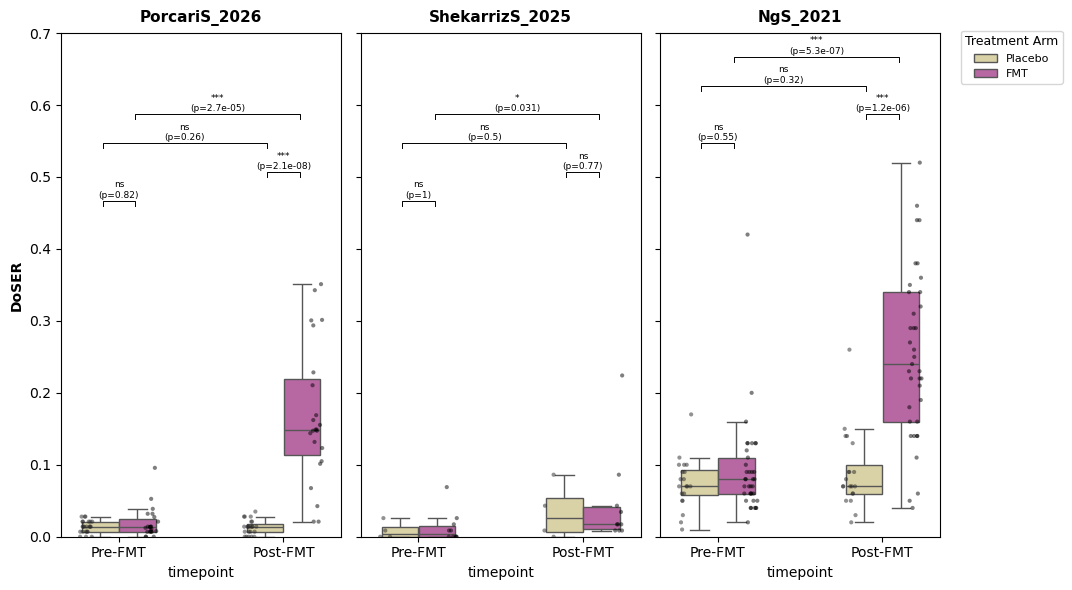

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, wilcoxon

# ----------------------------------------------------------------------
# `aggregated` already has: display_dataset, pre_fmt_id, arm, doser_pre,
# doser_post — built in the previous cell.
# ----------------------------------------------------------------------
datasets_to_plot = ['PorcariS_2026', 'ShekarrizS_2025', 'NgS_2021']

wide_df = aggregated[aggregated['display_dataset'].isin(datasets_to_plot)].copy()

long_df = pd.melt(
    wide_df,
    id_vars=['display_dataset', 'arm', 'pre_fmt_id'],
    value_vars=['doser_pre', 'doser_post'],
    var_name='timepoint', value_name='doser'
)
long_df['timepoint'] = long_df['timepoint'].map({'doser_pre': 'pre', 'doser_post': 'post'})
long_df['display_dataset'] = pd.Categorical(long_df['display_dataset'],
                                             categories=datasets_to_plot, ordered=True)

def sig_marker(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

def run_statistics(sub_df):
    results = []

    pre_placebo = sub_df.loc[(sub_df.timepoint == "pre") & (sub_df.arm == "placebo"), "doser"].dropna()
    pre_treatment = sub_df.loc[(sub_df.timepoint == "pre") & (sub_df.arm == "treatment"), "doser"].dropna()
    U, p = mannwhitneyu(pre_placebo, pre_treatment, alternative="two-sided")
    results.append({"comparison": "Pre placebo vs Pre treatment", "test": "Mann-Whitney", "p_value": p})

    post_placebo = sub_df.loc[(sub_df.timepoint == "post") & (sub_df.arm == "placebo"), "doser"].dropna()
    post_treatment = sub_df.loc[(sub_df.timepoint == "post") & (sub_df.arm == "treatment"), "doser"].dropna()
    U, p = mannwhitneyu(post_placebo, post_treatment, alternative="two-sided")
    results.append({"comparison": "Post placebo vs Post treatment", "test": "Mann-Whitney", "p_value": p})

    for arm in ["placebo", "treatment"]:
        arm_df = (
            sub_df[sub_df.arm == arm]
            .pivot(index="pre_fmt_id", columns="timepoint", values="doser")
            .dropna()
        )
        if len(arm_df):
            stat, p = wilcoxon(arm_df["pre"], arm_df["post"])
        else:
            p = np.nan
        results.append({"comparison": f"{arm.capitalize()} pre vs post", "test": "Wilcoxon", "p_value": p})

    return pd.DataFrame(results)

# ----------------------------------------------------------------------
# Plot one dataset onto a given ax. Only the leftmost panel gets a
# y-axis label; only the rightmost panel returns legend handles.
# ----------------------------------------------------------------------
def plot_dataset(ds, ax, show_ylabel=False):
    sub_df = long_df[long_df['display_dataset'] == ds].copy()
    stats_df = run_statistics(sub_df)

    print(f"\n=== {ds}: Stats ===")
    print(stats_df.to_string(index=False))

    sns.boxplot(
        data=sub_df, x='timepoint', y='doser', hue='arm',
        order=['pre', 'post'], hue_order=['placebo', 'treatment'],
        ax=ax, width=0.45, dodge=True, gap=0.02,
        palette={'placebo': '#E1D89F', 'treatment': '#C45BAA'},
        fliersize=0
    )

    sns.stripplot(
        data=sub_df, x='timepoint', y='doser', hue='arm',
        order=['pre', 'post'], hue_order=['placebo', 'treatment'],
        ax=ax, dodge=True, jitter=0.08, size=3,
        color='black', alpha=0.5, legend=False
    )

    x_pos = {
        ('pre', 'placebo'): -0.10,
        ('pre', 'treatment'): 0.10,
        ('post', 'placebo'): 0.90,
        ('post', 'treatment'): 1.10,
    }

    comparisons = [
        ("Pre placebo vs Pre treatment", ('pre', 'placebo'), ('pre', 'treatment')),
        ("Post placebo vs Post treatment", ('post', 'placebo'), ('post', 'treatment')),
        ("Placebo pre vs post", ('pre', 'placebo'), ('post', 'placebo')),
        ("Treatment pre vs post", ('pre', 'treatment'), ('post', 'treatment')),
    ]

    YMAX = 0.7
    highest_point = sub_df["doser"].max()
    base_y = max(highest_point + 0.02, 0.46)
    step = 0.040
    h = 0.007
    top_needed = base_y + (len(comparisons) - 1) * step + h
    if top_needed > (YMAX - 0.01):
        base_y -= top_needed - (YMAX - 0.01)

    for i, (comparison, g1, g2) in enumerate(comparisons):
        p = stats_df.loc[stats_df["comparison"] == comparison, "p_value"].iloc[0]
        x1, x2 = x_pos[g1], x_pos[g2]
        y = base_y + i * step

        ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y], color="black", linewidth=0.7)
        ax.text((x1+x2)/2, y+h*1.2, f"{sig_marker(p)}\n(p={p:.2g})",
                 ha="center", va="bottom", fontsize=6.5)

    ax.set_xlim(-0.35, 1.35)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Pre-FMT', 'Post-FMT'], fontsize=10)

    if show_ylabel:
        ax.set_ylabel('DoSER', fontsize=10, fontweight='bold')
    else:
        ax.set_ylabel('')

    # dataset name as the per-panel label (not redundant — each is unique)
    ax.set_title(ds, fontsize=11, fontweight='bold', pad=8)

    ax.set_ylim(0, 0.7)

    handles, labels = ax.get_legend_handles_labels()
    ax.legend_.remove() if ax.get_legend() else None  # strip per-panel legend

    return handles[:2], ["Placebo", "FMT"]

# ----------------------------------------------------------------------
# Build the combined figure: one row, one panel per dataset
# ----------------------------------------------------------------------
fig, axes = plt.subplots(1, len(datasets_to_plot), figsize=(3.2 * len(datasets_to_plot), 6), sharey=True)

legend_handles, legend_labels = None, None
for i, (ds, ax) in enumerate(zip(datasets_to_plot, axes)):
    h, l = plot_dataset(ds, ax, show_ylabel=(i == 0))
    if i == 0:
        legend_handles, legend_labels = h, l

# single shared legend for the whole figure
fig.legend(
    legend_handles, legend_labels,
    title="Treatment Arm",
    loc="upper left",
    bbox_to_anchor=(1.0, 0.95),
    fontsize=8, title_fontsize=9
)

plt.tight_layout()

# fig.savefig("engraftment_by_treatment_arm_combined.png", dpi=300, bbox_inches="tight")
fig.savefig(
    "engraftment_by_treatment_arm_combined.svg",
    bbox_inches="tight"
)

plt.show()

In [7]:
for ds in datasets_to_plot:
    for arm in ["placebo", "treatment"]:

        subset = long_df[
            (long_df["display_dataset"] == ds) &
            (long_df["arm"] == arm)
        ]

        duplicates = subset[
            subset.duplicated(
                subset=["pre_fmt_id", "timepoint"],
                keep=False
            )
        ]

        if not duplicates.empty:
            print(f"\n{'='*60}")
            print(f"DATASET: {ds} | ARM: {arm.upper()}")
            print(f"{'='*60}")
            print(
                duplicates[
                    ["pre_fmt_id", "timepoint", "doser"]
                ].sort_values(
                    ["pre_fmt_id", "timepoint"]
                ).to_string(index=False)
            )
        else:
            print(f"{ds} | {arm}: No duplicates")

PorcariS_2026 | placebo: No duplicates
PorcariS_2026 | treatment: No duplicates
ShekarrizS_2025 | placebo: No duplicates
ShekarrizS_2025 | treatment: No duplicates
NgS_2021 | placebo: No duplicates
NgS_2021 | treatment: No duplicates


0 duplicated rows across 0 (arm, pre_fmt_id) groups
Empty DataFrame
Columns: [display_dataset, arm, pre_fmt_id, timepoint, doser]
Index: []
Series([], dtype: int64)

=== PorcariS_2026: Stats ===
                    comparison         test  n_group1  median_group1  n_group2  median_group2      p_value
  Pre placebo vs Pre treatment Mann-Whitney        23       0.013986        23       0.013514 8.246256e-01
Post placebo vs Post treatment Mann-Whitney        23       0.013986        23       0.148936 2.110674e-08
           Placebo pre vs post     Wilcoxon        23       0.013986        23       0.013986 2.566039e-01
         Treatment pre vs post     Wilcoxon        23       0.013514        23       0.148936 2.698702e-05


/tmp/ipykernel_1399117/4096399059.py:171: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(



=== ShekarrizS_2025: Stats ===
                    comparison         test  n_group1  median_group1  n_group2  median_group2  p_value
  Pre placebo vs Pre treatment Mann-Whitney         4       0.004310        10       0.004310 1.000000
Post placebo vs Post treatment Mann-Whitney         4       0.025862        10       0.017241 0.773384
           Placebo pre vs post     Wilcoxon         4       0.004310         4       0.025862 0.500000
         Treatment pre vs post     Wilcoxon        10       0.004310        10       0.017241 0.031250

=== NgS_2021: Stats ===
                    comparison         test  n_group1  median_group1  n_group2  median_group2      p_value
  Pre placebo vs Pre treatment Mann-Whitney        20           0.07        37           0.08 5.453626e-01
Post placebo vs Post treatment Mann-Whitney        20           0.07        37           0.24 1.201133e-06
           Placebo pre vs post     Wilcoxon        20           0.07        20           0.07 3.194274e-01


/tmp/ipykernel_1399117/4096399059.py:171: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_1399117/4096399059.py:171: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/anaconda3/envs/jupyter_py11/lib/python3.11/site-packages/scipy/stats/_wilcoxon.py:181: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/tmp/ipykernel_1399117/4096399059.py:171: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


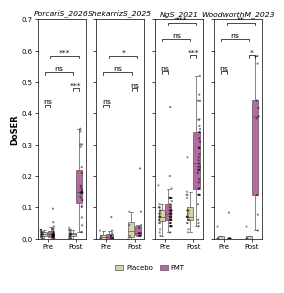

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, wilcoxon
plt.rcParams["svg.fonttype"] = "none"

# ----------------------------------------------------------------------
# `aggregated` already has: display_dataset, pre_fmt_id, arm, doser_pre,
# doser_post — built in the previous cell.
# ----------------------------------------------------------------------

# ------------------------------------------------------------------
# NATURE FIGURE SPEC
# - sans-serif (Arial/Helvetica), 5-7 pt body text, 0.5-0.75 pt lines
# - exact physical size in mm, no post-hoc cropping that would alter it
# ------------------------------------------------------------------
MM_TO_IN = 1 / 25.4
FIG_W_MM, FIG_H_MM = 65, 70
FIG_W_IN, FIG_H_IN = FIG_W_MM * MM_TO_IN, FIG_H_MM * MM_TO_IN

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 6,
    "axes.titlesize": 6,
    "axes.labelsize": 6,
    "xtick.labelsize": 5,
    "ytick.labelsize": 5,
    "legend.fontsize": 5,
    "legend.title_fontsize": 5.5,
    "axes.linewidth": 0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size": 2,
    "ytick.major.size": 2,
    "lines.linewidth": 0.6,
    "svg.fonttype": "none",  # keep text as text (editable/searchable) in the SVG
})

datasets_to_plot = ['PorcariS_2026', 'ShekarrizS_2025', 'NgS_2021', 'WoodworthM_2023']

wide_df = aggregated[aggregated['display_dataset'].isin(datasets_to_plot)].copy()

long_df = pd.melt(
    wide_df,
    id_vars=['display_dataset', 'arm', 'pre_fmt_id'],
    value_vars=['doser_pre', 'doser_post'],
    var_name='timepoint', value_name='doser'
)
long_df['timepoint'] = long_df['timepoint'].map({'doser_pre': 'pre', 'doser_post': 'post'})
long_df['display_dataset'] = pd.Categorical(long_df['display_dataset'],
                                             categories=datasets_to_plot, ordered=True)

ww = long_df[long_df['display_dataset'] == 'WoodworthM_2023']

# Every (arm, pre_fmt_id, timepoint) combo that appears more than once
dups = ww[ww.duplicated(subset=['arm', 'pre_fmt_id', 'timepoint'], keep=False)]
print(f"{len(dups)} duplicated rows across "
      f"{dups.groupby(['arm', 'pre_fmt_id']).ngroups} (arm, pre_fmt_id) groups")
print(dups.sort_values(['arm', 'pre_fmt_id', 'timepoint']).to_string(index=False))

# Summary: how many rows per ID per arm
print(ww.groupby(['arm', 'pre_fmt_id', 'timepoint']).size()
        .loc[lambda s: s > 1].sort_values(ascending=False))
def sig_marker(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

def run_statistics(sub_df):
    results = []

    pre_placebo = sub_df.loc[
        (sub_df.timepoint == "pre") & (sub_df.arm == "placebo"), "doser"
    ].dropna()

    pre_treatment = sub_df.loc[
        (sub_df.timepoint == "pre") & (sub_df.arm == "treatment"), "doser"
    ].dropna()

    U, p = mannwhitneyu(pre_placebo, pre_treatment, alternative="two-sided")

    results.append({
        "comparison": "Pre placebo vs Pre treatment",
        "test": "Mann-Whitney",
        "n_group1": len(pre_placebo),
        "median_group1": pre_placebo.median(),
        "n_group2": len(pre_treatment),
        "median_group2": pre_treatment.median(),
        "p_value": p
    })

    post_placebo = sub_df.loc[
        (sub_df.timepoint == "post") & (sub_df.arm == "placebo"), "doser"
    ].dropna()

    post_treatment = sub_df.loc[
        (sub_df.timepoint == "post") & (sub_df.arm == "treatment"), "doser"
    ].dropna()

    U, p = mannwhitneyu(post_placebo, post_treatment, alternative="two-sided")

    results.append({
        "comparison": "Post placebo vs Post treatment",
        "test": "Mann-Whitney",
        "n_group1": len(post_placebo),
        "median_group1": post_placebo.median(),
        "n_group2": len(post_treatment),
        "median_group2": post_treatment.median(),
        "p_value": p
    })

    for arm in ["placebo", "treatment"]:
        arm_df = (
            sub_df[sub_df.arm == arm]
            .pivot(index="pre_fmt_id", columns="timepoint", values="doser")
            .dropna()
        )

        if len(arm_df):
            stat, p = wilcoxon(arm_df["pre"], arm_df["post"])
        else:
            p = np.nan

        results.append({
            "comparison": f"{arm.capitalize()} pre vs post",
            "test": "Wilcoxon",
            "n_group1": len(arm_df),
            "median_group1": arm_df["pre"].median(),
            "n_group2": len(arm_df),
            "median_group2": arm_df["post"].median(),
            "p_value": p
        })

    return pd.DataFrame(results)

# ----------------------------------------------------------------------
# Plot one dataset onto a given ax. Only the leftmost panel gets a
# y-axis label; only the rightmost panel returns legend handles.
#
# KEY CHANGES FOR THE 80x50mm VERSION:
#  - dropped the "(p=0.0xx)" text under each bracket — at 5-7pt type,
#    two lines of text per bracket cannot fit in a ~2cm-tall panel
#    without either overlapping or shrinking below Nature's 5pt floor.
#    Only the significance stars are kept; full p-values belong in the
#    figure legend / a source-data table (still printed to stdout below).
#  - thinner brackets, smaller strip points, narrower boxes
#  - dataset name moved to a compact italic subtitle
# ----------------------------------------------------------------------
def plot_dataset(ds, ax, show_ylabel=False):
    sub_df = long_df[long_df['display_dataset'] == ds].copy()
    stats_df = run_statistics(sub_df)

    print(f"\n=== {ds}: Stats ===")
    print(stats_df.to_string(index=False))

    sns.boxplot(
        data=sub_df, x='timepoint', y='doser', hue='arm',
        order=['pre', 'post'], hue_order=['placebo', 'treatment'],
        ax=ax, width=0.45, dodge=True, gap=0.02,
        palette={'placebo': '#E1D89F', 'treatment': '#C45BAA'},
        fliersize=0, linewidth=0.5
    )

    sns.stripplot(
        data=sub_df, x='timepoint', y='doser', hue='arm',
        order=['pre', 'post'], hue_order=['placebo', 'treatment'],
        ax=ax, dodge=True, jitter=0.08, size=1.6,
        color='black', alpha=0.5, legend=False
    )

    x_pos = {
        ('pre', 'placebo'): -0.10,
        ('pre', 'treatment'): 0.10,
        ('post', 'placebo'): 0.90,
        ('post', 'treatment'): 1.10,
    }

    comparisons = [
        ("Pre placebo vs Pre treatment", ('pre', 'placebo'), ('pre', 'treatment')),
        ("Post placebo vs Post treatment", ('post', 'placebo'), ('post', 'treatment')),
        ("Placebo pre vs post", ('pre', 'placebo'), ('post', 'placebo')),
        ("Treatment pre vs post", ('pre', 'treatment'), ('post', 'treatment')),
    ]

    YMAX = 0.7
    highest_point = sub_df["doser"].max()
    base_y = max(highest_point + 0.015, 0.42)
    step = 0.052   # more vertical room per bracket since panels are short
    h = 0.008
    top_needed = base_y + (len(comparisons) - 1) * step + h
    if top_needed > (YMAX - 0.01):
        base_y -= top_needed - (YMAX - 0.01)

    for i, (comparison, g1, g2) in enumerate(comparisons):
        p = stats_df.loc[stats_df["comparison"] == comparison, "p_value"].iloc[0]
        x1, x2 = x_pos[g1], x_pos[g2]
        y = base_y + i * step

        ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color="black", linewidth=0.5)
        ax.text((x1 + x2) / 2, y + h * 1.1, sig_marker(p),
                 ha="center", va="bottom", fontsize=5.5)

    ax.set_xlim(-0.35, 1.35)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Pre', 'Post'], fontsize=5)
    ax.set_xlabel('')  # "Pre"/"Post" ticks already say this; drop the redundant axis label

    if show_ylabel:
        ax.set_ylabel('DoSER', fontsize=6, fontweight='bold', labelpad=2)
    else:
        ax.set_ylabel('')

    # compact italic subtitle instead of a bold title (saves vertical space)
    ax.set_title(ds, fontsize=5.5, style='italic', pad=3)

    ax.set_ylim(0, 0.7)
    ax.tick_params(pad=1.5)

    handles, labels = ax.get_legend_handles_labels()
    ax.legend_.remove() if ax.get_legend() else None  # strip per-panel legend

    return handles[:2], ["Placebo", "FMT"]

# ----------------------------------------------------------------------
# Build the combined figure: exact 80 x 50 mm canvas, one row, one
# panel per dataset. constrained_layout replaces tight_layout so the
# margins are solved analytically instead of by a bbox crop — this is
# what lets the final saved file stay EXACTLY 80x50mm.
# ----------------------------------------------------------------------
fig = plt.figure(figsize=(FIG_W_IN, FIG_H_IN), constrained_layout=True)
# a dedicated short legend row is reserved by the GridSpec itself, so
# constrained_layout allocates real space for it instead of the legend
# floating over the plot axes (which is what caused the earlier overlap).
gs = fig.add_gridspec(2, len(datasets_to_plot), height_ratios=[1, 0.14])
fig.get_layout_engine().set(w_pad=0.02, h_pad=0.01, wspace=0.03, hspace=0.02)

axes = [fig.add_subplot(gs[0, i]) for i in range(len(datasets_to_plot))]
for ax in axes[1:]:
    ax.sharey(axes[0])
    plt.setp(ax.get_yticklabels(), visible=False)

legend_handles, legend_labels = None, None
for i, (ds, ax) in enumerate(zip(datasets_to_plot, axes)):
    h, l = plot_dataset(ds, ax, show_ylabel=(i == 0))
    if i == 0:
        legend_handles, legend_labels = h, l

legend_ax = fig.add_subplot(gs[1, :])
legend_ax.axis("off")
legend_ax.legend(
    legend_handles, legend_labels,
    loc="center", ncol=2, fontsize=5, frameon=False,
    handlelength=1.2, handletextpad=0.4, columnspacing=1.0,
)

# ------------------------------------------------------------------
# IMPORTANT: do NOT use bbox_inches="tight" here. That re-crops the
# canvas to the drawn content and will change the physical output size
# away from 80x50mm. constrained_layout already solved the margins,
# so we save the figure at its literal figsize.
# ------------------------------------------------------------------
fig.savefig("engraftment_by_treatment_arm_combined_80x50mm.svg")
fig.savefig("engraftment_by_treatment_arm_combined_80x50mm.png", dpi=600)

plt.show()